<a href="https://colab.research.google.com/github/GabrieloAlonso/Portafolios/blob/main/Modelos__Supervisados__Clasificadores.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Lionel Messi | All Club Goals**

**Context**

This dataset contains all the stats of all goals of Lionel Andrés Messi.

**About Lionel Messi**

Lionel Andrés Messi, also known as Leo Messi, is an Argentine professional footballer who plays as a forward for Ligue 1 club Paris Saint-Germain and captains the Argentina national team.

* Born: June 24, 1987 (age 34 years), Rosario, Argentina

* Height: 1.69 m
* Spouse: Antonela Roccuzzo (m. 2017)
* Salary: 41 million USD (2022)
* Current teams: Paris Saint-Germain F.C. (#30 / Forward), Argentina nationalfootball team (#10 / Forward)
* Children: Mateo Messi Roccuzzo, Thiago Messi Roccuzzo, Ciro Messi Roccuzzo
* Awards: European Golden Shoe, FIFA World Player of the Year, MORE


**Content**

* data.csv file containing all goal's Season, Competition, Matchday, Venue, Date, Team, Opponent, Result, Position, Minute, At_score, Type, Assisted By


[Lionel Messi | All Club Goals](https://www.kaggle.com/datasets/azminetoushikwasi/-lionel-messi-all-club-goalsn)



# Objetivo del proyecto
Utilizar modelos supervisados para identificar las varaibleas siginificativas para predcir el minuto en que Lionel Messi anota un gol, ademas predecir en que minuto del partido Lionel Messi esta ganando con club deportivo

# Importación de Librerías

In [14]:
# Tratamiento de datos
import pandas as pd
import numpy as np
from numpy.linalg import cond

#Graficos
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns

# Procesado y modelado
from scipy.stats import pearsonr
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
import statsmodels as sms
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import jarque_bera
from scipy.stats import ttest_ind
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

# Visualización
import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns


# configuración de matplotlib
plt.rcParams['image.cmap']="bwr"
plt.rcParams['figure.dpi']="100"
plt.rcParams['savefig.bbox']="tight"
style.use('ggplot') or plt.style.use('ggplot')

# configuración de warnings
import warnings
warnings.filterwarnings('ignore')

# Pretratamiento de los Data Frame

In [17]:
data.head()

,Season,Competition,Matchday,Date,Venue,Club,Opponent,Result,Playing_Position,Minute,At_score,Type,Goal_assist
0,04/05,LaLiga,34,05-01/05,H,FC Barcelona,Albacete Balompie,2:00,CF,90+1,2:00,Left-footed shot,Ronaldinho Gaacho
1,05/06,UEFA Champions League,Group Stage,11-02/05,H,FC Barcelona,Panathinaikos Athens,5:00,RW,34,3:00,Left-footed shot,NaN
2,05/06,LaLiga,13,11/27/05,H,FC Barcelona,Racing Santander,4:01,RW,51,2:00,Left-footed shot,Samuel Etoo
3,05/06,LaLiga,19,1/15/06,H,FC Barcelona,Athletic Bilbao,2:01,RW,50,2:01,Left-footed shot,Mark van Bommel
4,05/06,LaLiga,20,1/22/06,H,FC Barcelona,Deportivo Alaves,2:00,CF,82,2:00,Left-footed shot,Ronaldinho Gaacho


In [18]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 704 entries, 0 to 703
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Season            704 non-null    object
 1   Competition       704 non-null    object
 2   Matchday          704 non-null    object
 3   Date              704 non-null    object
 4   Venue             704 non-null    object
 5   Club              704 non-null    object
 6   Opponent          704 non-null    object
 7   Result            704 non-null    object
 8   Playing_Position  704 non-null    object
 9   Minute            704 non-null    object
 10  At_score          704 non-null    object
 11  Type              703 non-null    object
 12  Goal_assist       490 non-null    object
dtypes: object(13)
memory usage: 71.6+ KB


In [19]:
data.isna().sum()

,0
Season,0
Competition,0
Matchday,0
Date,0
Venue,0
Club,0
Opponent,0
Result,0
Playing_Position,0
Minute,0


In [20]:
data["Goal_assist"] = data["Goal_assist"].replace([np.nan,"\t"], "Individual")

In [21]:
data[['Result H', 'Result A']] = data['Result'].str.split(':', expand=True)
data['Result H'] = data['Result H'].str.strip()
data['Result A'] = data['Result A'].str.split().str[0].str.strip()
data[['Result H', 'Result A']] = data[['Result H', 'Result A']].astype(int)

data[['At_score H', 'At_score A']] = data['At_score'].str.split(':', expand=True)
data['At_score H'] = data['At_score H'].str.strip()
data['At_score A'] = data['At_score A'].str.split().str[0].str.strip()
data[['At_score H', 'At_score A']] = data[['At_score H', 'At_score A']].astype(int)

# Función para convertir valores como '90+1' a 91
def convert_minute(minute_str):
    minute_str = str(minute_str)  # Convertir a cadena
    if '+' in minute_str:  # Manejar valores como '90+1'
        base, extra = minute_str.split('+')
        return int(base) + int(extra)
    return int(minute_str)  # Manejar valores enteros normales

# Aplicar la función a la columna "Minute"
data["Minute"] = data["Minute"].apply(convert_minute)
data

,Season,Competition,Matchday,Date,Venue,Club,Opponent,Result,Playing_Position,Minute,At_score,Type,Goal_assist,Result H,Result A,At_score H,At_score A
0,04/05,LaLiga,34,05-01/05,H,FC Barcelona,Albacete Balompie,2:00,CF,91,2:00,Left-footed shot,Ronaldinho Gaacho,2,0,2,0
1,05/06,UEFA Champions League,Group Stage,11-02/05,H,FC Barcelona,Panathinaikos Athens,5:00,RW,34,3:00,Left-footed shot,Individual,5,0,3,0
2,05/06,LaLiga,13,11/27/05,H,FC Barcelona,Racing Santander,4:01,RW,51,2:00,Left-footed shot,Samuel Etoo,4,1,2,0
3,05/06,LaLiga,19,1/15/06,H,FC Barcelona,Athletic Bilbao,2:01,RW,50,2:01,Left-footed shot,Mark van Bommel,2,1,2,1
4,05/06,LaLiga,20,1/22/06,H,FC Barcelona,Deportivo Alaves,2:00,CF,82,2:00,Left-footed shot,Ronaldinho Gaacho,2,0,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699,22/23,Ligue 1,21,2/1/23,A,Paris Saint-Germain,Montpellier HSC,1:3,SS,72,0:2,Left-footed shot,Fabián Ruiz,1,3,0,2
700,22/23,Ligue 1,22,2/4/23,H,Paris Saint-Germain,FC Toulouse,2:1,SS,58,2:1,Left-footed shot,Achraf Hakimi,2,1,2,1
701,22/23,Ligue 1,24,2/19/23,H,Paris Saint-Germain,LOSC Lille,4:3,CF,95,4:3,Direct free kick,Individual,4,3,4,3
702,22/23,Ligue 1,25,2/26/23,A,Paris Saint-Germain,Olympique Marseille,0:3,CF,29,0:2,Right-footed shot,Kylian Mbappé,0,3,0,2


In [22]:
data["Win"] = np.where(
    ((data["Venue"] == "H") & (data["Result H"] > data["Result A"])) |  # Condición para local
    ((data["Venue"] == "A") & (data["Result A"] > data["Result H"])),  # Condición para visitante
    True,  # Si se cumple alguna condición, es True
    False  # Si no se cumple, es False
)

data = data.drop(["Result","At_score"],axis=1)

In [23]:
data["Type"] = data["Type"].replace([np.nan], "Long distance kick")

In [24]:
data.isna().sum()

,0
Season,0
Competition,0
Matchday,0
Date,0
Venue,0
Club,0
Opponent,0
Playing_Position,0
Minute,0
Type,0


In [25]:
columns_to_encode = [
    "Season", "Competition", "Matchday", "Date", "Venue",
    "Club", "Opponent", "Playing_Position", "Type", "Goal_assist", "Win"
]

# Aplicar Label Encoding a cada columna
label_encoders = {}  # Para almacenar los encoders (opcional)
for col in columns_to_encode:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
    label_encoders[col] = le  # Guardar el encoder (opcional)

In [27]:
data = data[data["Minute"] <= 95]
data.head()

,Season,Competition,Matchday,Date,Venue,Club,Opponent,Playing_Position,Minute,Type,Goal_assist,Result H,Result A,At_score H,At_score A,Win
0,0,3,27,87,1,0,5,2,91,5,58,2,0,2,0,1
1,1,8,42,204,1,0,65,5,34,5,28,5,0,3,0,1
2,1,3,4,239,1,0,71,5,51,5,59,4,1,2,0,1
3,1,3,10,121,1,0,8,5,50,5,41,2,1,2,1,1
4,1,3,12,136,1,0,32,2,82,5,58,2,0,2,0,1


In [28]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 703 entries, 0 to 703
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Season            703 non-null    int64
 1   Competition       703 non-null    int64
 2   Matchday          703 non-null    int64
 3   Date              703 non-null    int64
 4   Venue             703 non-null    int64
 5   Club              703 non-null    int64
 6   Opponent          703 non-null    int64
 7   Playing_Position  703 non-null    int64
 8   Minute            703 non-null    int64
 9   Type              703 non-null    int64
 10  Goal_assist       703 non-null    int64
 11  Result H          703 non-null    int64
 12  Result A          703 non-null    int64
 13  At_score H        703 non-null    int64
 14  At_score A        703 non-null    int64
 15  Win               703 non-null    int64
dtypes: int64(16)
memory usage: 93.4 KB


In [29]:
data.describe()

,Season,Competition,Matchday,Date,Venue,Club,Opponent,Playing_Position,Minute,Type,Goal_assist,Result H,Result A,At_score H,At_score A,Win
count,703.000000,703.000000,703.000000,703.000000,703.000000,703.000000,703.000000,703.000000,703.000000,703.000000,703.000000,703.000000,703.000000,703.000000,703.000000,703.000000
mean,9.917496,3.846373,25.697013,227.580370,0.597440,0.045519,53.455192,3.940256,51.840683,5.652916,32.681366,2.674253,1.779516,1.630156,1.136558,0.890469
std,4.501537,2.116079,14.823197,132.855722,0.490763,0.208588,29.646357,1.949319,25.858759,1.742428,17.874150,1.995866,1.698342,1.481049,1.300280,0.312526
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6.000000,3.000000,13.000000,108.500000,0.000000,0.000000,24.500000,2.000000,30.000000,5.000000,22.000000,1.000000,0.000000,0.000000,0.000000,1.000000
50%,10.000000,3.000000,25.000000,228.000000,1.000000,0.000000,56.000000,5.000000,54.000000,5.000000,28.000000,2.000000,1.000000,1.000000,1.000000,1.000000
75%,13.000000,3.000000,42.000000,339.500000,1.000000,0.000000,76.500000,5.000000,75.000000,7.000000,47.000000,4.000000,3.000000,3.000000,2.000000,1.000000
max,18.000000,9.000000,47.000000,454.000000,1.000000,1.000000,97.000000,8.000000,95.000000,11.000000,70.000000,8.000000,8.000000,8.000000,7.000000,1.000000


# Analisís Exploratorio

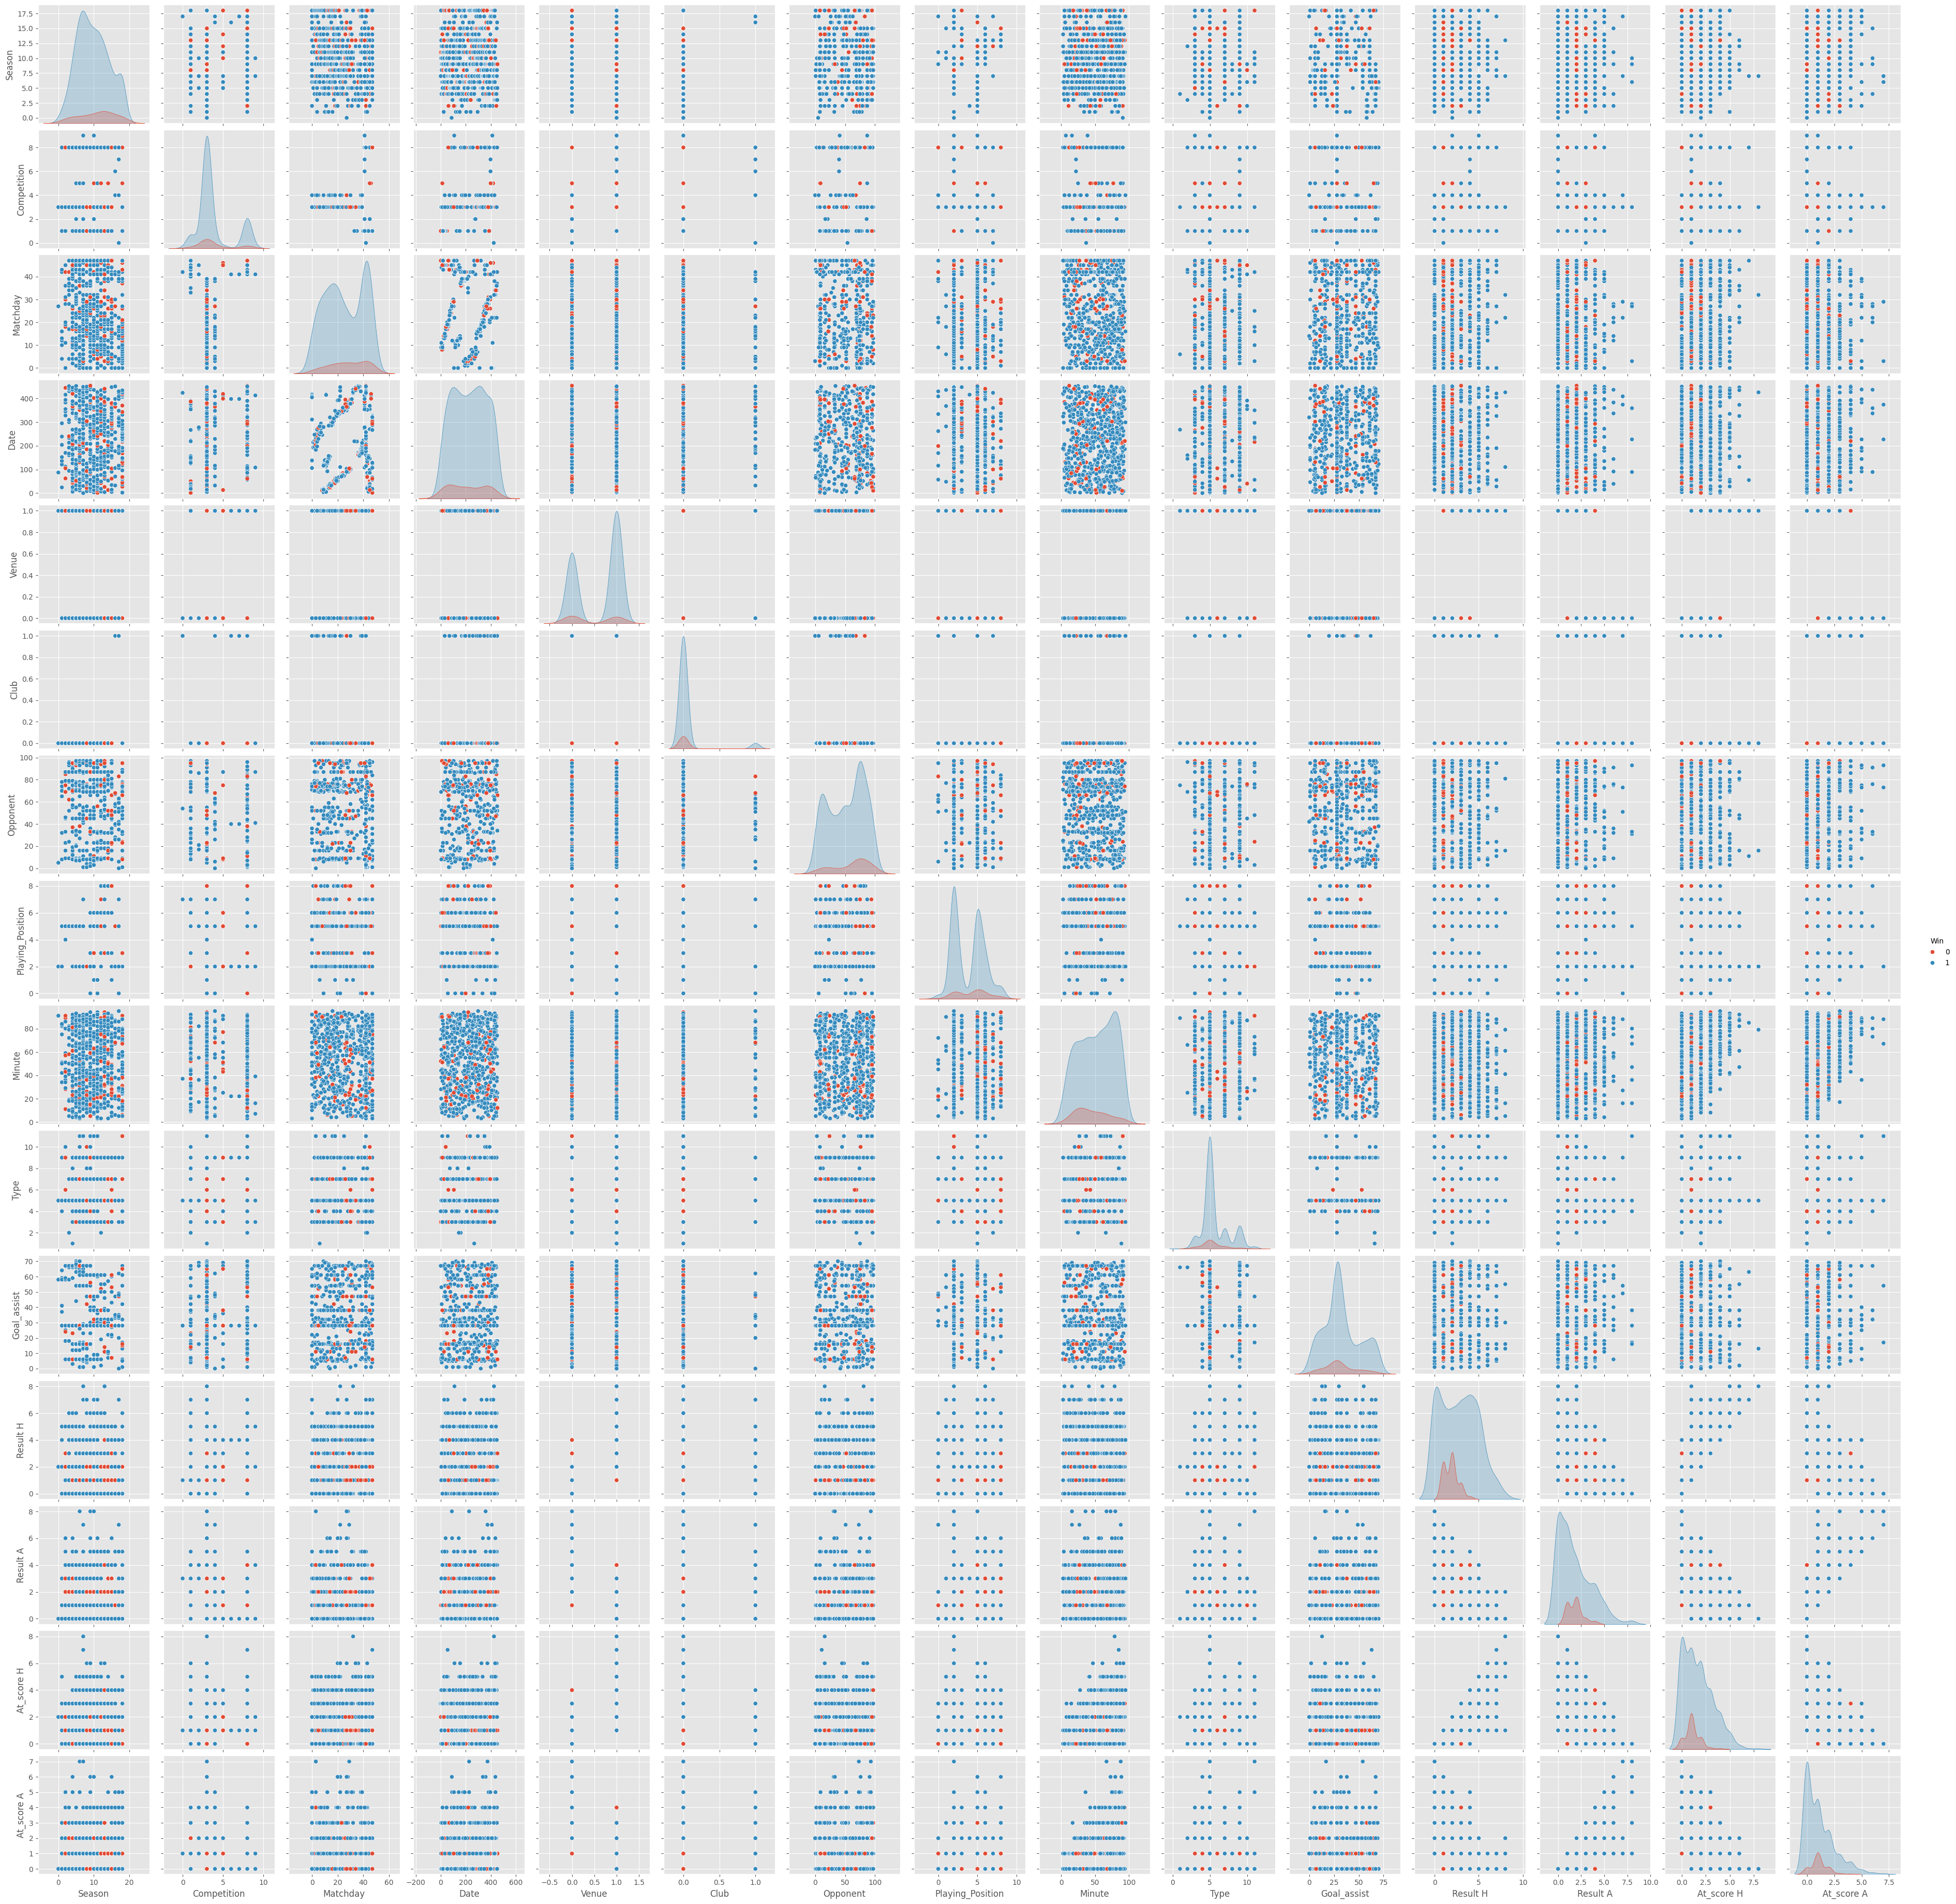

In [30]:
sns.pairplot(data, hue="Win")

<Axes: xlabel='Win', ylabel='Minute'>

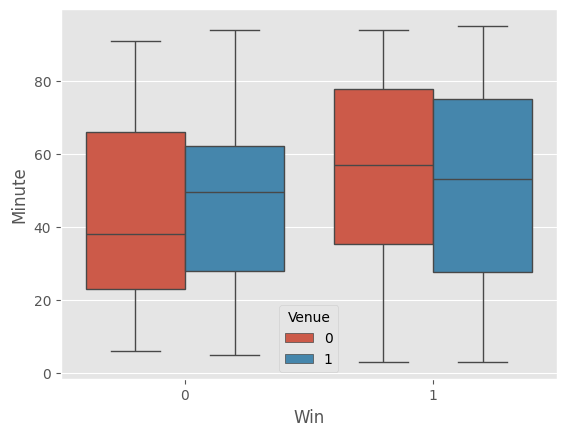

In [31]:
sns.boxplot(data=data, x="Win", y="Minute", hue="Venue")

<Axes: xlabel='At_score H', ylabel='Count'>

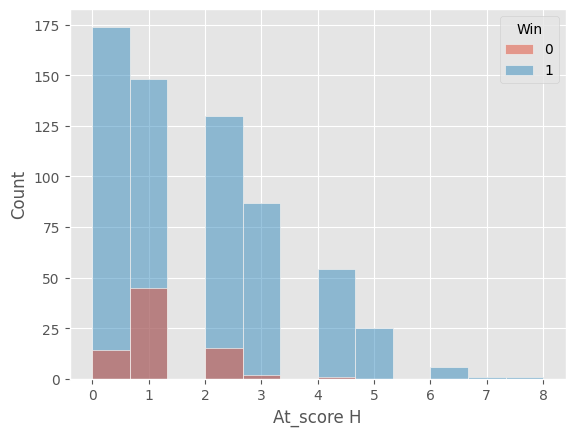

In [32]:
sns.histplot(data =data, x=data["At_score H"] , hue="Win")

<Axes: xlabel='At_score H', ylabel='Minute'>

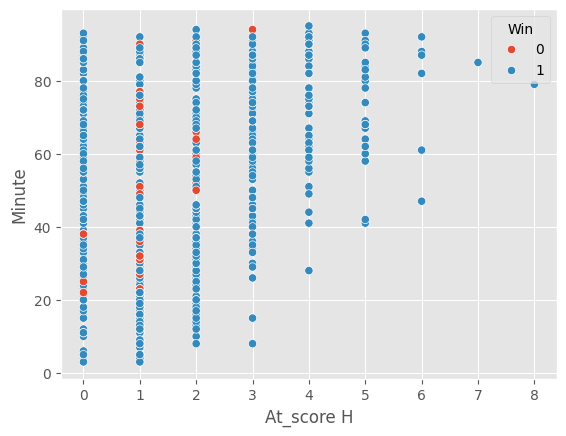

In [33]:
sns.scatterplot(data=data, y="Minute", x="At_score H", hue = "Win")

In [34]:
numeric_data = data.select_dtypes(include=['float64', 'int64'])

# Calcular la matriz de correlación
numeric_data.corr().round(3)

,Season,Competition,Matchday,Date,Venue,Club,Opponent,Playing_Position,Minute,Type,Goal_assist,Result H,Result A,At_score H,At_score A,Win
Season,1.000,-0.003,-0.098,0.042,-0.017,0.323,-0.020,0.006,-0.045,-0.090,-0.123,-0.006,0.048,-0.013,0.053,-0.074
Competition,-0.003,1.000,0.448,0.086,0.039,0.122,-0.163,-0.038,-0.054,0.043,0.014,0.007,-0.080,-0.044,-0.078,-0.008
Matchday,-0.098,0.448,1.000,0.046,0.067,-0.018,-0.108,-0.028,-0.068,0.021,-0.006,0.065,-0.131,0.024,-0.135,-0.061
Date,0.042,0.086,0.046,1.000,-0.006,0.040,0.004,-0.023,0.039,0.035,0.041,-0.005,0.021,0.016,0.025,0.031
Venue,-0.017,0.039,0.067,-0.006,1.000,-0.016,-0.055,0.018,-0.059,0.070,0.016,0.740,-0.713,0.655,-0.677,0.093
Club,0.323,0.122,-0.018,0.040,-0.016,1.000,-0.058,-0.091,-0.002,-0.004,0.021,-0.053,0.081,-0.042,0.066,0.033
Opponent,-0.020,-0.163,-0.108,0.004,-0.055,-0.058,1.000,0.018,0.004,-0.012,0.010,-0.002,0.073,-0.002,0.080,-0.087
Playing_Position,0.006,-0.038,-0.028,-0.023,0.018,-0.091,0.018,1.000,-0.011,-0.100,0.092,-0.031,0.025,-0.042,0.001,-0.079
Minute,-0.045,-0.054,-0.068,0.039,-0.059,-0.002,0.004,-0.011,1.000,0.068,-0.018,-0.129,0.059,0.337,0.344,0.079
Type,-0.090,0.043,0.021,0.035,0.070,-0.004,-0.012,-0.100,0.068,1.000,-0.009,0.043,-0.049,0.072,-0.019,0.037


<Axes: >

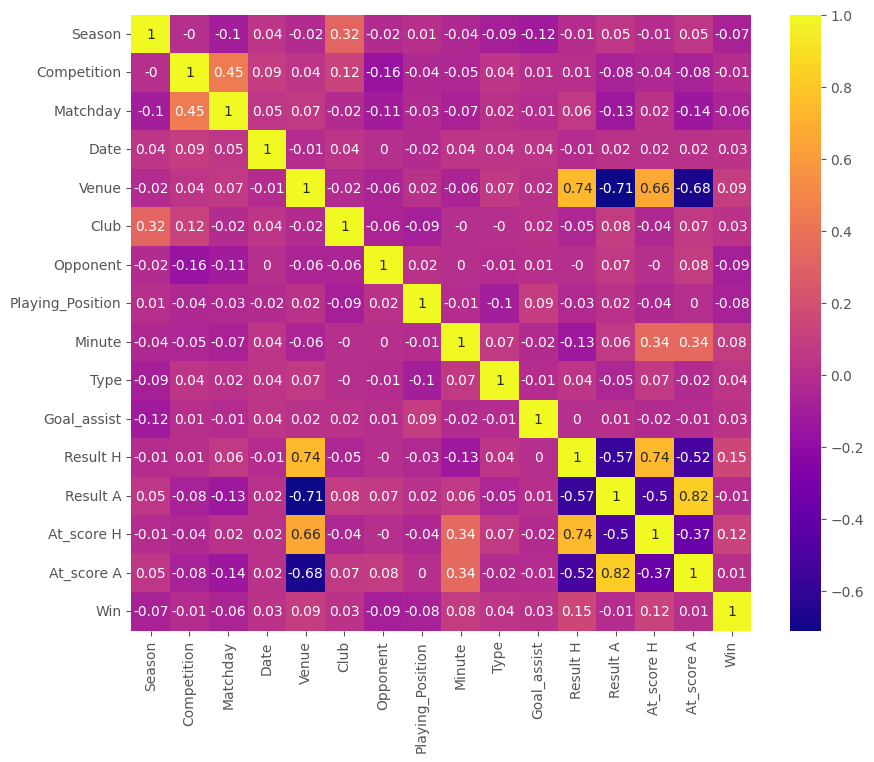

In [35]:
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_data.corr().round(2), annot=True, cmap="plasma")

# **Regresión lineal múltiple**
Predicción del minuto en que Messi anota un gol

#Modelo 1

In [36]:
X_orig = pd.DataFrame(data= data, columns =["Season", "Competition", "Matchday", "Date", "Venue",
                                            "Club", "Opponent", "Playing_Position", "Type", "Goal_assist",
                                            "Result H", "Result A", "At_score H", "At_score A",
                                            "Win"
                                            ])
y_orig =data["Minute"]


In [37]:
X_train, X_test, y_train, y_test = train_test_split(X_orig, y_orig, random_state=123,train_size = 0.8) #75% para entrenamiento, 25% para prueba
df = pd.concat([X_train,y_train], axis=1)
X_train.shape
X_test.shape
y_train.shape
y_test.shape


(141,)

In [38]:
X_train = sm.add_constant(X_train, prepend=True)
modelo = sm.OLS(y_train, X_train)
modelo = modelo.fit()
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                 Minute   R-squared:                       0.587
Model:                            OLS   Adj. R-squared:                  0.576
Method:                 Least Squares   F-statistic:                     51.80
Date:                Wed, 21 Jan 2026   Prob (F-statistic):           1.50e-94
Time:                        18:32:00   Log-Likelihood:                -2376.8
No. Observations:                 562   AIC:                             4786.
Df Residuals:                     546   BIC:                             4855.
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               42.3501      5.287  

## Normalidad de los errores

In [39]:
resid_val = modelo.resid
fitted_val = modelo.predict()
print(f"Media de los residuales: {resid_val.mean()}")
print(f"Desviación estándar de los residuales: {resid_val.std()}")

Media de los residuales: 6.812612949056448e-13
Desviación estándar de los residuales: 16.62933736800316


In [40]:
stat, p_value, _, _ = jarque_bera(resid_val)
print(f"Estadistico de Jarque-Bera: {stat:.4f}")
print(f"P-value: {p_value}")

if p_value > 0.05:
    print("No se rechaza H0: Los residuos parecen normales")
else:
    print("Se rechaza H0: Los residuos NO son normales")

Estadistico de Jarque-Bera: 6.6740
P-value: 0.03554422732541966
Se rechaza H0: Los residuos NO son normales


Text(0.5, 1.0, 'Fitted vs Observed')

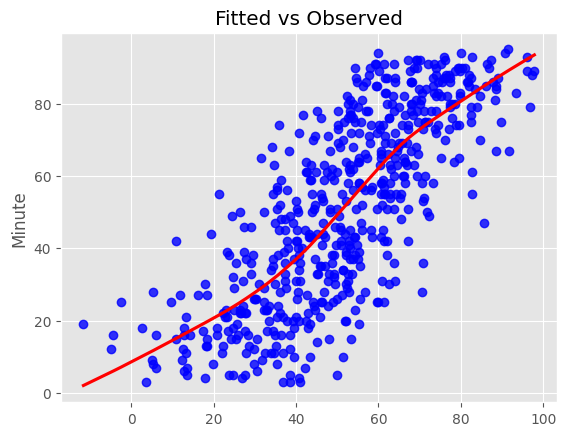

In [41]:
sns.regplot(x=fitted_val,y = y_train, color='blue', lowess=True, line_kws={'color':'red'})
plt.title('Fitted vs Observed')

### Autocorrelación

### Prueba de Durbin-Watson

### Hipótesis
- $H_0$: No hay autocorrelación en los residuos ($\rho = 0$).
- $H_1$: Existe autocorrelación en los residuos ($\rho \neq 0$).

In [42]:
dw_stat = durbin_watson(modelo.resid)
print(f"Estadístico de Durbin-Watson: {dw_stat}")

# 2: No hay autocorrelación
# < 2: Posible autocorrelación positiva
# > 2: Posible autocorrelación negativa

Estadístico de Durbin-Watson: 2.0137951774046097


In [43]:
# Prueba de Breusch-Pagan
bp = het_breuschpagan(resid_val, modelo.model.exog)

# Resultados: estadístico, p-valor, estadístico F y p-valor F
print(f"Estadístico LM: {bp[0]}")
print(f"P-valor: {bp[1]}")
print(f"Estadístico F: {bp[2]}")
print(f"P-valor F: {bp[3]}")

# Si el p-valor es < 0.05, se rechaza H0 (existe heterocedasticidad).

Estadístico LM: 52.48083360623297
P-valor: 4.702482251175249e-06
Estadístico F: 3.749225680335955
P-valor F: 2.4725753849777283e-06


valores limite de apalancamiento: 0.060498220640569395


0.060498220640569395

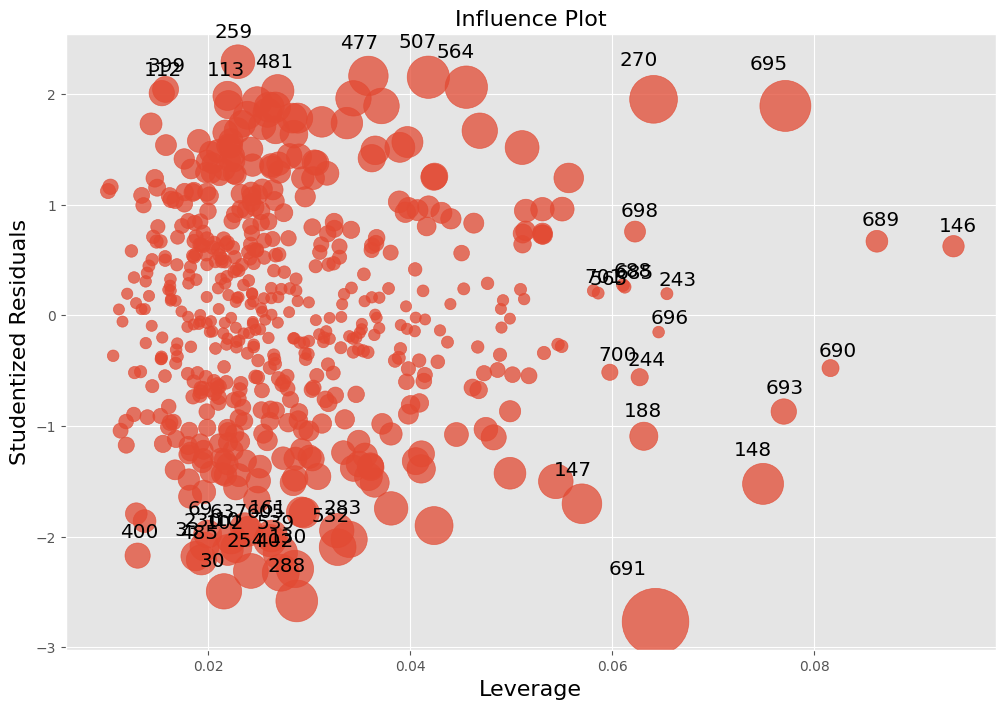

In [44]:
# Leverage points: Apalancamiento

# Influence points: cook distance (Gráfico de influencia)
fig, ax= plt.subplots(figsize=(12,8))
sm.graphics.influence_plot(modelo, alpha= 0.05, ax=ax,criterion="cooks")

# Para determinar los valores límites del apalancamiento, se utiliza la fórmula 2*p/n, donde
#p: el número de coeficientes
#n: el número de observaciones
print("valores limite de apalancamiento:", (2*(X_train.shape[1]+1))/X_train.shape[0])

2*((X_train.shape[1]+1)/X_train.shape[0])

Text(0.5, 1.0, 'Fitted vs Observed')

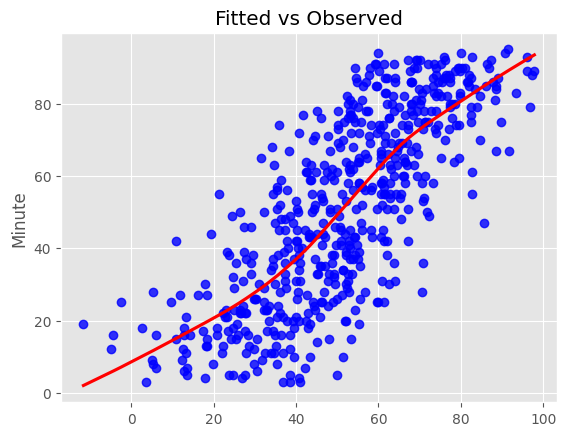

In [45]:
sns.regplot(x=fitted_val,y = y_train, color='blue', lowess=True, line_kws={'color':'red'})
plt.title('Fitted vs Observed')

# Modelo 2

Usando las variables con P menor de 0.05

In [46]:
X_orig = pd.DataFrame(data= data, columns =[
                                            "Result H", "Result A", "At_score H", "At_score A",

                                            ])
y_orig =data["Minute"]

In [47]:
X_train, X_test, y_train, y_test = train_test_split(X_orig, y_orig, random_state=123,train_size = 0.8) #75% para entrenamiento, 25% para prueba
df = pd.concat([X_train,y_train], axis=1)
X_train.shape
X_test.shape
y_train.shape
y_test.shape

(141,)

In [48]:
X_train = sm.add_constant(X_train, prepend=True)
modelo = sm.OLS(y_train, X_train)
modelo = modelo.fit()
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                 Minute   R-squared:                       0.578
Model:                            OLS   Adj. R-squared:                  0.575
Method:                 Least Squares   F-statistic:                     191.1
Date:                Wed, 21 Jan 2026   Prob (F-statistic):          5.24e-103
Time:                        18:32:02   Log-Likelihood:                -2382.8
No. Observations:                 562   AIC:                             4776.
Df Residuals:                     557   BIC:                             4797.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         46.2996      1.983     23.348      0.0

valores limite de apalancamiento: 0.021352313167259787


0.021352313167259787

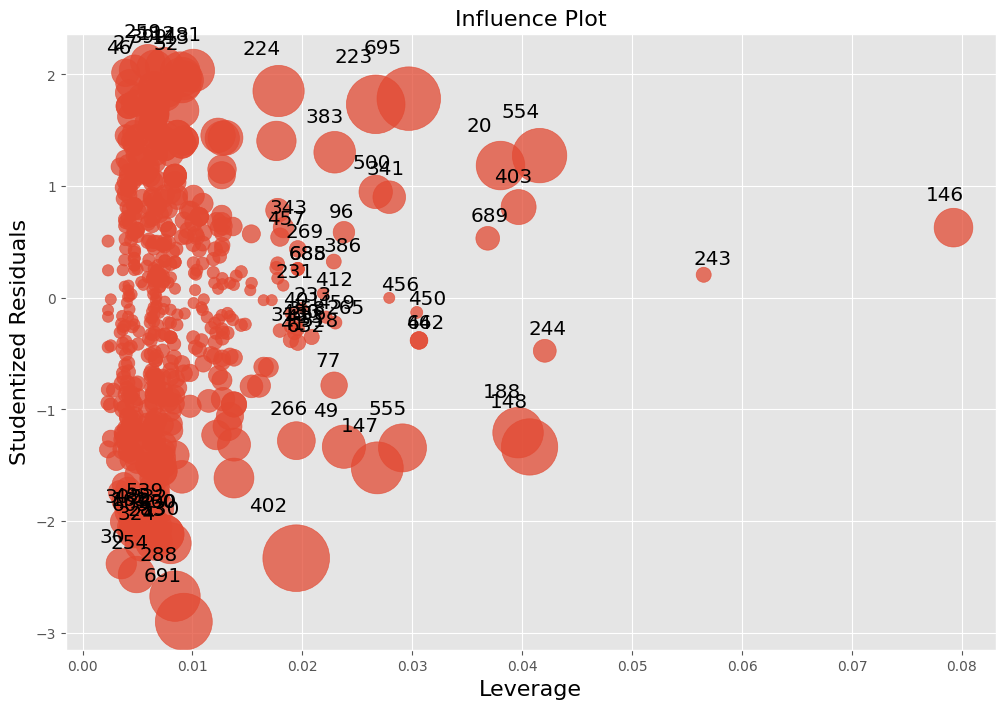

In [49]:
# Leverage points: Apalancamiento

# Influence points: cook distance (Gráfico de influencia)
fig, ax= plt.subplots(figsize=(12,8))
sm.graphics.influence_plot(modelo, alpha= 0.05, ax=ax,criterion="cooks")

# Para determinar los valores límites del apalancamiento, se utiliza la fórmula 2*p/n, donde
#p: el número de coeficientes
#n: el número de observaciones
print("valores limite de apalancamiento:", (2*(X_train.shape[1]+1))/X_train.shape[0])

2*((X_train.shape[1]+1)/X_train.shape[0])

# Modelo 3

In [50]:
# Lista de índices a eliminar
indices_a_eliminar = [146,243,188,148,244,403,20,691,288,402,695,689,450,30,254,555,554]

# Eliminar las filas de X_train
X_train = X_train.drop(indices_a_eliminar)
y_train = y_train.drop(indices_a_eliminar)

In [51]:
X_train = sm.add_constant(X_train, prepend=True)
modelo = sm.OLS(y_train, X_train)
modelo = modelo.fit()
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                 Minute   R-squared:                       0.599
Model:                            OLS   Adj. R-squared:                  0.596
Method:                 Least Squares   F-statistic:                     201.6
Date:                Wed, 21 Jan 2026   Prob (F-statistic):          1.20e-105
Time:                        18:32:03   Log-Likelihood:                -2294.8
No. Observations:                 545   AIC:                             4600.
Df Residuals:                     540   BIC:                             4621.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         46.6236      2.006     23.245      0.0

In [52]:
resid_val = modelo.resid
fitted_val = modelo.predict()
print(f"Media de los residuales: {resid_val.mean()}")
print(f"Desviación estándar de los residuales: {resid_val.std()}")

Media de los residuales: 8.291838164099518e-15
Desviación estándar de los residuales: 16.324978233866762


Text(0.5, 1.0, 'Fitted vs Observed')

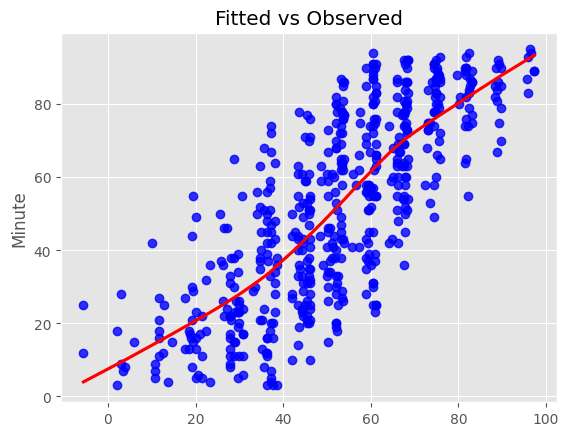

In [53]:
sns.regplot(x=fitted_val,y = y_train, color='blue', lowess=True, line_kws={'color':'red'})
plt.title('Fitted vs Observed')

# Conclusión de Regresión Lineal Múltiple

A continuación, se presenta un análisis comparativo de los tres modelos de regresión lineal múltiple basado en las métricas proporcionadas:

## Modelo 1
- **R² (R-squared):** 0.587  
  - El modelo explica aproximadamente el 58.7% de la variabilidad de la variable dependiente (`Minute`).
- **Adj. R² (R-squared ajustado):** 0.576  
  - El R² ajustado es ligeramente menor que el R², lo que indica que algunas variables pueden no ser significativas.
- **F-statistic:** 51.87
  - El valor F es alto, lo que sugiere que el modelo en su conjunto es significativo.
- **Variables significativas (p < 0.05):**  
  - `const`, `Result H`, `Result A`, `At_score H`, `At_score A`.
- **Durbin-Watson:** 2.014  
  - El valor está cerca de 2, lo que sugiere que no hay autocorrelación significativa en los residuos.
- **Jarque-Bera (JB):** 6.674
  - El valor de JB tiene un p-valor de 0.0355, lo que indica que los residuos podrían no seguir una distribución normal (aunque no es concluyente al 5% de significancia).
- **Problemas:**  
  - Muchas variables no son significativas (`Season`, `Competition`, `Matchday`, etc.), lo que sugiere que el modelo podría simplificarse.

## Modelo 2
- **R² (R-squared):** 0.578  
  - El modelo explica aproximadamente el 57.8% de la variabilidad de la variable dependiente.
- **Adj. R² (R-squared ajustado):** 0.575  
  - El R² ajustado es cercano al R², lo que indica que el modelo es más eficiente que el primero.
- **F-statistic:** 191.1  
  - El valor F es mucho más alto que en el primer modelo, lo que sugiere un mejor ajuste global.
- **Variables significativas (p < 0.05):**  
  - `const`, `Result H`, `Result A`, `At_score H`, `At_score A`.
- **Durbin-Watson:** 1.998  
  - El valor está cerca de 2, lo que indica que no hay autocorrelación significativa en los residuos.
- **Jarque-Bera (JB):** 7.227  
  - El valor de JB tiene un p-valor de 0.0270, lo que sugiere que los residuos podrían no seguir una distribución normal (aunque no es concluyente al 5% de significancia).
- **Mejoras:**  
  - Este modelo es más simple (solo 4 variables predictoras) y tiene un mejor ajuste global (F-statistic más alto).

## Modelo 3
- **R² (R-squared):** 0.599  
  - El modelo explica aproximadamente el 59.9% de la variabilidad de la variable dependiente.
- **Adj. R² (R-squared ajustado):** 0.596  
  - El R² ajustado es cercano al R², lo que indica que el modelo es eficiente.
- **F-statistic:** 201.6  
  - El valor F es el más alto de los tres modelos, lo que sugiere un mejor ajuste global.
- **Variables significativas (p < 0.05):**  
  - `const`, `Result H`, `Result A`, `At_score H`, `At_score A`.
- **Durbin-Watson:** 2.015  
  - El valor está cerca de 2, lo que indica que no hay autocorrelación significativa en los residuos.
- **Jarque-Bera (JB):** 7.731  
  - El valor de JB tiene un p-valor de 0.0206, lo que sugiere que los residuos no siguen una distribución normal (a un nivel de significancia del 5%).
- **Mejoras:**  
  - Este modelo tiene el R² más alto y el F-statistic más alto, lo que indica que es el mejor ajustado.
  - Se eliminaron filas con posibles valores atípicos o ruido, lo que mejoró el rendimiento del modelo.

## Comparación General
- **R² y R² ajustado:**  
  - El **Modelo 3** tiene el R² más alto (0.599), seguido del **Modelo 1** (0.587) y el **Modelo 2** (0.578).  
  - Esto indica que el **Modelo 3** explica mejor la variabilidad de la variable dependiente.
- **F-statistic:**  
  - El **Modelo 3** tiene el F-statistic más alto (201.6), lo que sugiere que es el modelo con el mejor ajuste global.
- **Simplicidad:**  
  - El **Modelo 2** y el **Modelo 3** son más simples que el **Modelo 1**, ya que incluyen solo 4 variables predictoras significativas (`Result H`, `Result A`, `At_score H`, `At_score A`).
- **Eliminación de filas:**  
  - En el **Modelo 3**, se eliminaron filas específicas que podrían haber sido valores atípicos o ruido, lo que mejoró el rendimiento del modelo.
- **Durbin-Watson:**  
  - En los tres modelos, el valor de Durbin-Watson está cerca de 2, lo que indica que no hay autocorrelación significativa en los residuos.
- **Jarque-Bera (JB):**  
  - En el **Modelo 3**, el valor de JB tiene un p-valor de 0.0206, lo que sugiere que los residuos no siguen una distribución normal (a un nivel de significancia del 5%).  


## Conclusión Final
- El **Modelo 3** es el mejor de los tres, ya que tiene el R² más alto, el F-statistic más alto y un R² ajustado cercano al R².  
  Además, es más simple y eficiente que los otros dos modelos.
- Las variables más importantes para predecir `Minute` son:
  - `Result H`, `Result A`, `At_score H`, `At_score A`.
- Se recomienda utilizar el **Modelo 3** para futuras predicciones, ya que es el más robusto y explicativo.
- Aunque los residuos en el **Modelo 3** no siguen una distribución normal (según Jarque-Bera), esto no invalida necesariamente el modelo, ya que la regresión lineal es robusta a pequeñas desviaciones de la normalidad.


# **Regresión Logística**

In [54]:
numeric_data.head()

,Season,Competition,Matchday,Date,Venue,Club,Opponent,Playing_Position,Minute,Type,Goal_assist,Result H,Result A,At_score H,At_score A,Win
0,0,3,27,87,1,0,5,2,91,5,58,2,0,2,0,1
1,1,8,42,204,1,0,65,5,34,5,28,5,0,3,0,1
2,1,3,4,239,1,0,71,5,51,5,59,4,1,2,0,1
3,1,3,10,121,1,0,8,5,50,5,41,2,1,2,1,1
4,1,3,12,136,1,0,32,2,82,5,58,2,0,2,0,1


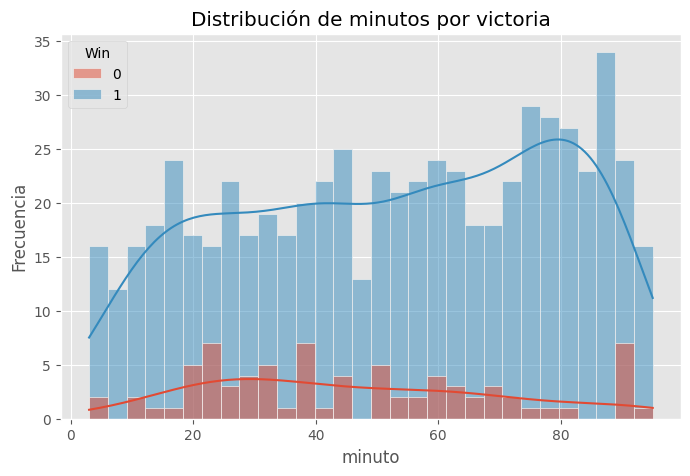

In [55]:
# Análisis exploratorio
plt.figure(figsize=(8, 5))
sns.histplot(data=numeric_data, x="Minute", hue="Win", kde=True, bins=30, alpha=0.5)
plt.title("Distribución de minutos por victoria")
plt.xlabel("minuto")
plt.ylabel("Frecuencia")
plt.show()

In [56]:
#  Prueba T entre clases
grupo_0 = numeric_data[numeric_data["Win"] == 0]["Minute"]
grupo_1 = numeric_data[numeric_data["Win"] == 1]["Minute"]
t_stat, p_value = ttest_ind(grupo_0, grupo_1, equal_var=False)
print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: -2.2394410492921275
P-value: 0.027353124415390447


T-statistic: -2.239

Este valor indica la magnitud de la diferencia entre las medias de los dos grupos. Un valor negativo sugiere que la media del grupo_0 es menor que la del grupo_1.

P-value:   0.0273
Este valor es menor que el nivel de significancia común de 0.05, lo que indica que la diferencia entre las medias de los dos grupos es estadísticamente significativa.

In [57]:
# División de datos en train y test
X = numeric_data[["Minute"]]
y = numeric_data["Win"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=27)

In [58]:
# Creación del modelo logístico
modelo = LogisticRegression()
modelo.fit(X_train, y_train)

LogisticRegression()

In [59]:
# A la matriz de predictores se le tiene que añadir una columna de 1s para el intercept del modelo
X_train = sm.add_constant(X_train, prepend=True)
modelo = sm.Logit(endog=y_train, exog=X_train)
modelo = modelo.fit()
print(modelo.summary())

Optimization terminated successfully.
         Current function value: 0.330496
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                    Win   No. Observations:                  562
Model:                          Logit   Df Residuals:                      560
Method:                           MLE   Df Model:                            1
Date:                Wed, 21 Jan 2026   Pseudo R-squ.:                 0.01607
Time:                        18:32:03   Log-Likelihood:                -185.74
converged:                       True   LL-Null:                       -188.77
Covariance Type:            nonrobust   LLR p-value:                   0.01377
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.5122      0.277      5.450      0.000       0.968       2.056
Minute         0.0132      0.


El modelo tiene un Pseudo R² de 0.01607, lo que indica que explica una pequeña parte de la variabilidad de la variable dependiente (Win).
El LLR p-value (0.01377) sugiere que el modelo es significativamente mejor que un modelo sin predictores.

Significancia de los Predictores:

* El intercepto es significativo, y la variable Minute también es significativa (p = 0.015).

* Esto sugiere que el minuto del juego (Minute) tiene un impacto estadísticamente significativo en la probabilidad de ganar.

Recomendaciones:

El Pseudo $R^{2}$ sigue siendo bajo, lo que indica que se podrían incluir más variables predictoras para mejorar el ajuste del modelo

In [60]:
# Intervalos de confianza para los coeficientes del modelo
# ==============================================================================
intervalos_ci = modelo.conf_int(alpha=0.05)
intervalos_ci = pd.DataFrame(intervalos_ci)
intervalos_ci.columns = ["2.5%", "97.5%"]
intervalos_ci

,2.5%,97.5%
const,0.968343,2.056023
Minute,0.002567,0.023765


In [61]:
# Predicción de probabilidades
# ==============================================================================
predicciones = modelo.predict(exog = X_train)
predicciones[177:1111]

,0
519,0.919369
553,0.938397
622,0.845078
692,0.867707
560,0.904606
...,...
24,0.876514
294,0.867707
544,0.873636
697,0.903463


In [62]:
# Clasificación predicha
# ==============================================================================
clasificacion = np.where(predicciones < 0.86, 0, 1)
clasificacion

array([1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0,
       0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1,
       0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1,

In [63]:
# Predicciones en todo el rango de X
# ==============================================================================
# Se crea un vector con nuevos valores interpolados en el rango de observaciones.
grid_X = np.linspace(
            start = min(numeric_data["Minute"]),
            stop  = max(numeric_data["Minute"]),
            num   = 200
         ).reshape(-1,1)

grid_X = sm.add_constant(grid_X, prepend=True)
predicciones = modelo.predict(exog = grid_X)

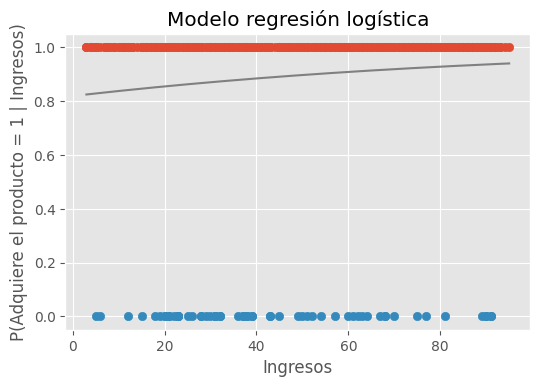

In [64]:
fig, ax = plt.subplots(figsize=(6, 3.84))


ax.scatter(
    X_train.loc[(y_train == 1).values, X_train.columns[1]],
    y_train[(y_train == 1).values].values
)
ax.scatter(
    X_train.loc[(y_train == 0).values, X_train.columns[1]],
    y_train[(y_train == 0).values].values
)
ax.plot(grid_X[:, 1], predicciones, color = "gray")
ax.set_title("Modelo regresión logística")
ax.set_ylabel("P(Adquiere el producto = 1 | Ingresos)")
ax.set_xlabel("Ingresos");

In [65]:
# Cálculo de métricas usando la matriz de confusión

# Convierte a la clase (0 o 1) usando un umbral de 0.86
y_pred_labels = (modelo.predict(sm.add_constant(X_test, prepend=True)) >= 0.86).astype(int)

#Matriz de confusión
cm = confusion_matrix(y_test, y_pred_labels)

# Métricas

accuracy = accuracy_score(y_test, y_pred_labels)
precision = precision_score(y_test, y_pred_labels)
recall = recall_score(y_test, y_pred_labels)
f1 = f1_score(y_test, y_pred_labels)
report = classification_report(y_test, y_pred_labels)
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

Accuracy: 0.7589
Precision: 0.8739
Recall: 0.8455
F1-Score: 0.8595


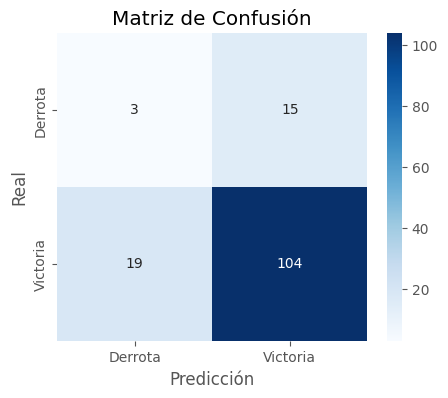

In [66]:

# Mostrar matriz de confusión
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Derrota", "Victoria"], yticklabels=["Derrota", "Victoria"])
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de Confusión")
plt.show()

##Interpretación de las Métricas
**Accuracy (0.7589):**

El modelo tiene una buena capacidad general para clasificar correctamente las instancias, pero no es perfecto.

**Precision (0.8739):**

El modelo tiene una alta precisión, lo que significa que cuando predice una clase positiva, es muy probable que sea correcta.

**Recall (0.8455):**

El modelo tiene una alta sensibilidad, lo que significa que es bueno para identificar la mayoría de las instancias positivas.

**F1-Score (0.8595):**

El equilibrio entre precisión y recall es bueno, lo que indica que el modelo no sacrifica una métrica por la otra.

**Conclusión**

* El modelo tiene un buen rendimiento general, con un accuracy del 75.89% y un F1-score del 85.95%.

* La alta precision (87.39%) sugiere que el modelo es confiable cuando predice la clase positiva.

* La alta recall (84.55%) indica que el modelo es efectivo para identificar la mayoría de las instancias positivas.

* La matriz de confusión proporciona una visión detallada de los aciertos y errores del modelo, lo que es útil para identificar áreas de mejora.

# Análisis discriminante Lineal (LDA)

In [67]:
numeric_data.head()

,Season,Competition,Matchday,Date,Venue,Club,Opponent,Playing_Position,Minute,Type,Goal_assist,Result H,Result A,At_score H,At_score A,Win
0,0,3,27,87,1,0,5,2,91,5,58,2,0,2,0,1
1,1,8,42,204,1,0,65,5,34,5,28,5,0,3,0,1
2,1,3,4,239,1,0,71,5,51,5,59,4,1,2,0,1
3,1,3,10,121,1,0,8,5,50,5,41,2,1,2,1,1
4,1,3,12,136,1,0,32,2,82,5,58,2,0,2,0,1


In [68]:
# División de los datos en train y test
# ==============================================================================
X = numeric_data.drop(columns = 'Win')
y = numeric_data['Win']

X_train, X_test, y_train, y_test = train_test_split(
                                        X,
                                        y.values.reshape(-1,1),
                                        train_size   = 0.8,
                                        random_state = 27,
                                        shuffle      = True
                                    )

In [69]:
# Creación del modelo utilizando matrices como en scikitlearn
# ==============================================================================
lda = LDA()
lda.fit(X_train,y_train)
pred = lda.predict(X_test)
print(pred)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


In [70]:
print('Prior Probs are - ',lda.priors_)
print('Class Means are  - ',lda.means_)
print('Coeff are - ',lda.coef_)

Prior Probs are -  [0.10498221 0.89501779]
Class Means are  -  [[1.12542373e+01 4.00000000e+00 2.98305085e+01 2.07593220e+02
  4.74576271e-01 3.38983051e-02 5.96610169e+01 4.28813559e+00
  4.35423729e+01 5.50847458e+00 3.01525424e+01 1.84745763e+00
  1.74576271e+00 1.03389831e+00 1.01694915e+00]
 [9.94035785e+00 3.79324056e+00 2.47574553e+01 2.32415507e+02
  6.10337972e-01 5.16898608e-02 5.21769384e+01 3.87475149e+00
  5.23260437e+01 5.66202783e+00 3.23061630e+01 2.75944334e+00
  1.79522863e+00 1.66202783e+00 1.14711730e+00]]
Coeff are -  [[-8.72541474e-02  4.17535170e-02 -3.00776775e-02  1.35103130e-03
   2.57756304e-01  7.19944797e-01 -1.21247039e-02 -1.11537179e-01
   1.87469202e-02  5.99150951e-04  7.72192039e-03  5.00734974e-01
   2.86026908e-01 -1.55587337e-01  5.30700124e-02]]


In [71]:
cm = confusion_matrix(y_test,pred)
print(cm)

[[  1  17]
 [  1 122]]


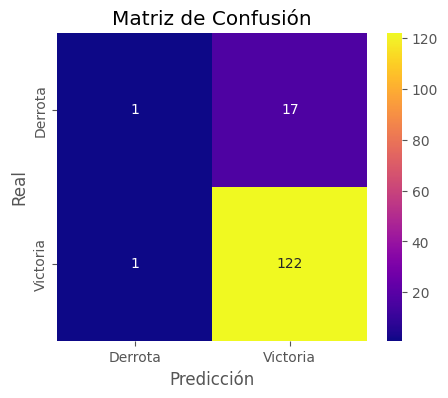

In [72]:


# Mostrar matriz de confusión
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="plasma", xticklabels=["Derrota", "Victoria"], yticklabels=["Derrota", "Victoria"])
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de Confusión")
plt.show()

In [73]:
## Metricas de evaluación
accuracy = accuracy_score(
            y_true    = y_test,
            y_pred    = pred,
            normalize = True
           )
print("")
print(f"El accuracy de test es: {100*accuracy}%")

accuracy = accuracy_score(y_test, pred)
precision = precision_score(y_test, pred)
recall = recall_score(y_test, pred)
f1 = f1_score(y_test, pred)
auc_roc = roc_auc_score(y_test, pred)

# Imprimir métricas
print("Exactitud (Accuracy):", accuracy)
print("Precisión (Precision):", precision)
print("Recall (Sensitivity):", recall)
print("F1-score:", f1)
print("AUC-ROC:", auc_roc)


El accuracy de test es: 87.2340425531915%
Exactitud (Accuracy): 0.8723404255319149
Precisión (Precision): 0.8776978417266187
Recall (Sensitivity): 0.991869918699187
F1-score: 0.9312977099236641
AUC-ROC: 0.5237127371273713


# Conclusión

1. Prior Probabilities (Probabilidades Previas) [0.10498221 0.89501779]

* La clase 0 tiene una probabilidad previa del 10.50%, mientras que la clase 1 tiene una probabilidad previa del 89.50%. Esto indica que el conjunto de datos está desbalanceado, con una mayoría de instancias pertenecientes a la clase 1.

2. Class Means (Medias de las Clases):

* Estas son las medias de las características (variables predictoras) para cada clase. Ayudan a entender cómo se distribuyen las características en cada clase.

3. Coefficients (Coeficientes del Modelo):

* Estos son los coeficientes del modelo LDA, que indican la contribución de cada característica en la discriminación entre las clases.



4. Métricas de Evaluación:

* Accuracy (Exactitud): 0.8723 (87.23%), el modelo clasifica correctamente el 87.23% de las instancias.

* Dado el desbalanceo de clases, esta métrica puede ser engañosa, ya que el modelo tiende a favorecer la clase mayoritaria (clase 1).

* Precision (Precisión): 0.8777 (87.77%) todas las predicciones positivas que hizo el modelo, el 87.77% son correctas. Esto indica que el modelo es bastante preciso al predecir la clase 1.

* Recall (Sensibilidad): 0.9918 (99.18%), el modelo identifica correctamente el 99.18% de todas las instancias positivas reales. Esto sugiere que el modelo es muy bueno para detectar la clase 1.

* F1-Score: 0.9313 (93.13%), es el promedio armónico entre precision y recall. Un valor de 93.13% indica un buen equilibrio entre precisión y recall, lo que sugiere que el modelo es robusto en la clasificación de ambas clases.

* AUC-ROC: 0.5237 (52.37%) El área bajo la curva ROC es 52.37%, lo que indica que el modelo tiene un rendimiento cercano al azar en la discriminación entre las clases.Esto sugiere que el modelo no es muy efectivo para distinguir entre las clases, especialmente dada la alta sensibilidad y el desbalanceo de clases.

# Analisis Discriminate Cuadrático (QDA)

In [74]:
numeric_data.head()

,Season,Competition,Matchday,Date,Venue,Club,Opponent,Playing_Position,Minute,Type,Goal_assist,Result H,Result A,At_score H,At_score A,Win
0,0,3,27,87,1,0,5,2,91,5,58,2,0,2,0,1
1,1,8,42,204,1,0,65,5,34,5,28,5,0,3,0,1
2,1,3,4,239,1,0,71,5,51,5,59,4,1,2,0,1
3,1,3,10,121,1,0,8,5,50,5,41,2,1,2,1,1
4,1,3,12,136,1,0,32,2,82,5,58,2,0,2,0,1


In [75]:
# División de los datos en train y test
# ==============================================================================
X = numeric_data.drop(columns = 'Win')
y = numeric_data['Win']

X_train, X_test, y_train, y_test = train_test_split(
                                        X,
                                        y.values.reshape(-1,1),
                                        train_size   = 0.8,
                                        random_state = 27,
                                        shuffle      = True
                                    )

In [76]:
# Creación del modelo utilizando matrices como en scikitlearn
# ==============================================================================
qda = QDA()
qda.fit(X_train,y_train)


QuadraticDiscriminantAnalysis()

In [77]:
pred = qda.predict(X_test)
print(pred)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 0
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1]


In [78]:
print('Mean for class 0 is - ',qda.means_[0])
print('Mean for class 1 is - ',qda.means_[1])
print('Prior probalbilities - ',qda.priors_)

Mean for class 0 is -  [1.12542373e+01 4.00000000e+00 2.98305085e+01 2.07593220e+02
 4.74576271e-01 3.38983051e-02 5.96610169e+01 4.28813559e+00
 4.35423729e+01 5.50847458e+00 3.01525424e+01 1.84745763e+00
 1.74576271e+00 1.03389831e+00 1.01694915e+00]
Mean for class 1 is -  [9.94035785e+00 3.79324056e+00 2.47574553e+01 2.32415507e+02
 6.10337972e-01 5.16898608e-02 5.21769384e+01 3.87475149e+00
 5.23260437e+01 5.66202783e+00 3.23061630e+01 2.75944334e+00
 1.79522863e+00 1.66202783e+00 1.14711730e+00]
Prior probalbilities -  [0.10498221 0.89501779]


In [79]:
pred = qda.predict(X_test)
cm = confusion_matrix(y_test,pred)
print(cm)

[[  9   9]
 [  0 123]]


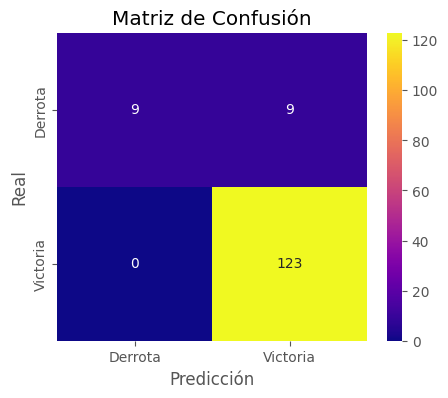

In [80]:
# Mostrar matriz de confusión
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="plasma", xticklabels=["Derrota", "Victoria"], yticklabels=["Derrota", "Victoria"])
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de Confusión")
plt.show()

In [81]:
## Metricas de evaluación
accuracy = accuracy_score(
            y_true    = y_test,
            y_pred    = pred,
            normalize = True
           )
print("")
print(f"El accuracy de test es: {100*accuracy}%")

accuracy = accuracy_score(y_test, pred)
precision = precision_score(y_test, pred)
recall = recall_score(y_test, pred)
f1 = f1_score(y_test, pred)
auc_roc = roc_auc_score(y_test, pred)

# Imprimir métricas
print("Exactitud (Accuracy):", accuracy)
print("Precisión (Precision):", precision)
print("Recall (Sensitivity):", recall)
print("F1-score:", f1)
print("AUC-ROC:", auc_roc)


El accuracy de test es: 93.61702127659575%
Exactitud (Accuracy): 0.9361702127659575
Precisión (Precision): 0.9318181818181818
Recall (Sensitivity): 1.0
F1-score: 0.9647058823529412
AUC-ROC: 0.75


1. Medias de las Clases (Class Means): Estas son las medias de las características (variables predictoras) para la clase 0. Estas medias ayudan a entender cómo se distribuyen las características en cada clase.


2. Prior Probabilities (Probabilidades Previas): [0.10498221 0.89501779]. Estas son las probabilidades previas de cada clase en el conjunto de datos. La clase 0 tiene una probabilidad previa del 10.50%, mientras que la clase 1 tiene una probabilidad previa del 89.50%. Esto indica que el conjunto de datos está desbalanceado, con una mayoría de instancias pertenecientes a la clase 1.


3. Métricas de Evaluación
* Accuracy (Exactitud): 0.9362 (93.62%) El modelo clasifica correctamente el 93.62% de las instancias. Este es un valor alto, pero dado el desbalanceo de clases es importante revisar otras métricas.

* Precision (Precisión): 0.9318 (93.18%) de todas las predicciones positivas que hizo el modelo, el 93.18% son correctas. Esto indica que el modelo es bastante preciso al predecir la clase 1.

* Recall (Sensibilidad): 1.0 (100%), el modelo identifica correctamente el 100% de todas las instancias positivas reales. Esto sugiere que el modelo es excelente para detectar la clase 1.

* F1-Score: 0.9647 (96.47%) es el promedio armónico entre precision y recall. Un valor de 96.47% indica un excelente equilibrio entre precisión y recall, lo que sugiere que el modelo es muy robusto en la clasificación de ambas clases.

* AUC-ROC: 0.75 (75%) el área bajo la curva ROC es 75%, lo que indica que el modelo tiene un buen rendimiento en la discriminación entre las clases. Este valor es mejor que el obtenido con el modelo LDA, lo que sugiere que el QDA es más efectivo para distinguir entre las clases.

# Comparación de los modelos

**Regresión Lineal Multiple**

**Rendimiento Predictivo**

* El modelo reducido con filas eliminadas es el mejor, con un R² de 59.9% y un F-statistic de 201.6.

* El modelo completo tiene un R² ligeramente menor (58.7%) y problemas de multicolinealidad.

* El modelo reducido sin eliminar filas tiene un R² de 57.8%, pero es más simple y eficiente.

**Simplicidad y Eficiencia**

* El modelo reducido (con o sin eliminación de filas) es más simple y eficiente que el modelo completo, ya que incluye solo 4 predictores significativos.

* La eliminación de filas con valores atípicos o influyentes mejoró significativamente el rendimiento del modelo.

**Multicolinealidad**

* El modelo completo tiene un número de condición alto (2.07e+03), lo que sugiere problemas de multicolinealidad.

* Los modelos reducidos no tienen este problema, ya que incluyen solo predictores significativos y no correlacionados.


**Clasificación**

**Rendimiento General**

El QDA es el modelo con mejor rendimiento, seguido del LDA y luego la Regresión Logística.

El QDA tiene el accuracy más alto (93.62%) y el F1-score más alto (96.47%).

* Precisión y Recall: El QDA y el LDA tienen un recall muy alto (100% y 99.18%, respectivamente), lo que indica que son excelentes para identificar la clase positiva (victoria). La Regresión Logística tiene un recall más bajo (84.55%), pero aún es aceptable.

**Discriminación entre Clases**

* El QDA tiene el AUC-ROC más alto (75%), lo que indica que es el mejor para distinguir entre las clases.

* El LDA tiene un AUC-ROC bajo (52.37%), lo que sugiere que no es efectivo para distinguir entre las clases.

**Balanceo de Clases**

* Todos los modelos tienen dificultades con el desbalanceo de clases, ya que la clase positiva (victoria) es mayoritaria.

* Se recomienda aplicar técnicas de balanceo de clases para mejorar el rendimiento de los modelos, especialmente para la clase negativa (derrota).

# Conclusiones

Dada la naturaleza del conjunto de datos seleccionado existe cierto desbalance entre la variable predictora "Win". Como resultado un modelo supervisado poco robusto no tendara el mejor desmpeño para predecir futuros eventos.

Por lo tanto, modelos supervisados más robustos tienen un mejor desempeño tal es el caso del modelo QDA el cual fuel el mejor, sus métricas fueron las sobresalientes para predecir en que minuto del partido de futbol Lionel Messi estara ganado.

Sin embargo, necesario hacer un escalamiento de la variables predictoras y ver el desempeño de todos los modelos para identiciar si dicho escalamiento es mejora sus metricas, ademas es necesario considerar que el conjunto de datos puede tener otras variables predictoras mas significativas que ayuden a mejorar el desempeño de cada modelo.